In [4]:
import pandas as pd
import numpy as np
import time
import warnings

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, FastICA
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings("ignore")

# Load dataset
df = pd.read_csv("../data/data.csv")

df = df.drop(columns=["id", "Unnamed: 32"])

X = df.drop(columns=["diagnosis"])
y = (df["diagnosis"] == "M").astype(int)

print("Dataset:", X.shape)
print("Classes:", y.value_counts().to_dict())

Dataset: (569, 30)
Classes: {0: 357, 1: 212}


In [5]:
models = {
    "SVM": SVC(kernel="rbf", probability=True, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    )
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

In [6]:
results = []

configurations = {
    "Original": None,
    "PCA": [1, 2, 3, 5, 10],
    "FastICA": [1, 2, 3, 5, 10]
}

for method, components_list in configurations.items():

    component_values = [None] if components_list is None else components_list

    for n_components in component_values:

        for model_name, model in models.items():

            steps = [("scaler", StandardScaler())]

            if method == "PCA":
                steps.append(
                    ("reduction", PCA(n_components=n_components))
                )

            elif method == "FastICA":
                steps.append(
                    ("reduction", FastICA(
                        n_components=n_components,
                        random_state=42,
                        max_iter=1000,
                        tol=0.001
                    ))
                )

            steps.append(("classifier", model))

            pipeline = Pipeline(steps)

            start = time.time()

            scores = cross_validate(
                pipeline,
                X,
                y,
                cv=cv,
                scoring=scoring,
                n_jobs=-1
            )

            elapsed = time.time() - start

            results.append({
                "Method": method,
                "Components": n_components if n_components else 30,
                "Model": model_name,
                "Accuracy": scores["test_accuracy"].mean(),
                "Precision": scores["test_precision"].mean(),
                "Recall": scores["test_recall"].mean(),
                "F1": scores["test_f1"].mean(),
                "ROC_AUC": scores["test_roc_auc"].mean(),
                "Time": elapsed
            })

results_df = pd.DataFrame(results)

results_df.to_csv("../results/model_comparison.csv", index=False)

results_df.sort_values("ROC_AUC", ascending=False).head(15)

,Method,Components,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Time
1,Original,30,Logistic Regression,0.973669,0.986258,0.943632,0.963341,0.995314,4.854210
16,PCA,5,SVM,0.964881,0.972101,0.934219,0.951639,0.995262,0.050016
21,PCA,10,Logistic Regression,0.977177,0.977576,0.962348,0.969161,0.994854,0.036955
36,FastICA,5,SVM,0.963111,0.959327,0.943522,0.950191,0.994795,0.056525
37,FastICA,5,Logistic Regression,0.966636,0.981607,0.929568,0.953447,0.994662,0.044582
20,PCA,10,SVM,0.973653,0.976502,0.952935,0.964179,0.994597,0.056521
17,PCA,5,Logistic Regression,0.963142,0.961332,0.943632,0.950118,0.994595,0.034579
0,Original,30,SVM,0.977162,0.981047,0.957586,0.968777,0.994525,6.311578
41,FastICA,10,Logistic Regression,0.975408,0.990909,0.943522,0.965953,0.994390,0.066531
40,FastICA,10,SVM,0.957833,0.948101,0.938870,0.943064,0.994197,0.113526


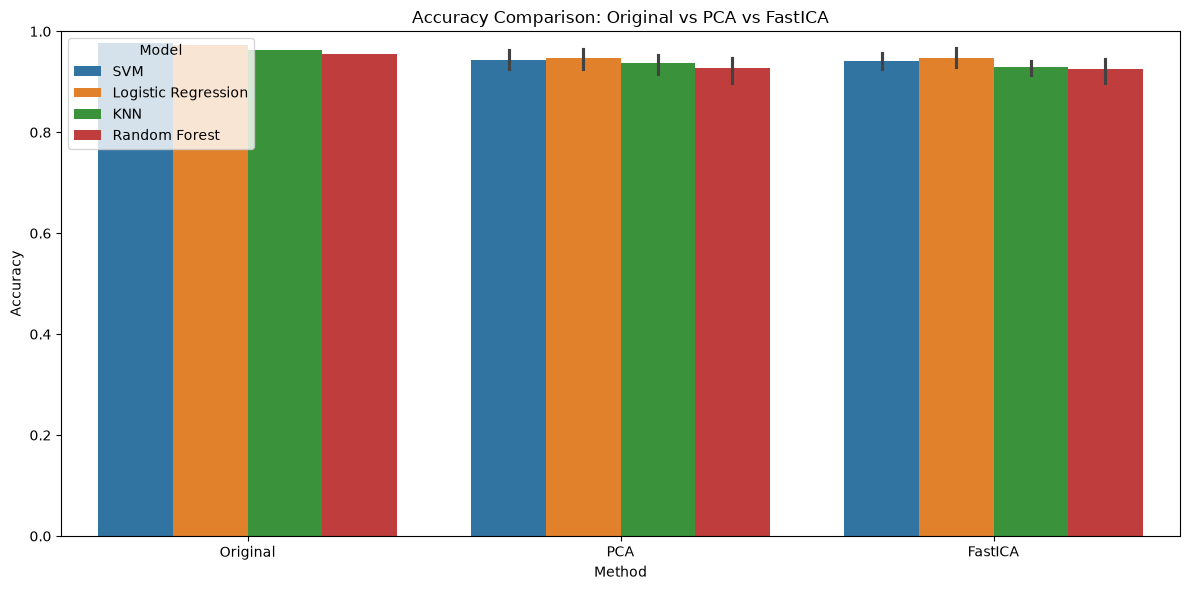

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Method",
    y="Accuracy",
    hue="Model"
)

plt.title("Accuracy Comparison: Original vs PCA vs FastICA")
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig("../results/accuracy_comparison.png")
plt.show()

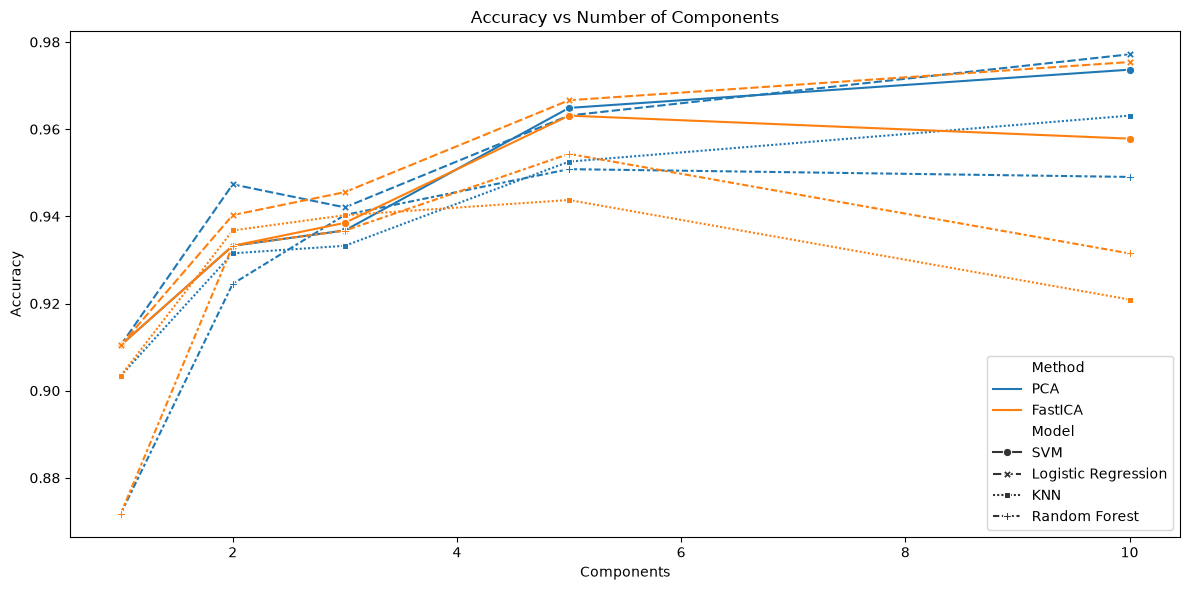

In [8]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=results_df[results_df["Method"] != "Original"],
    x="Components",
    y="Accuracy",
    hue="Method",
    style="Model",
    markers=True
)

plt.title("Accuracy vs Number of Components")
plt.tight_layout()
plt.savefig("../results/components_comparison.png")
plt.show()

In [9]:
print(results_df.columns.tolist())


['Method', 'Components', 'Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC', 'Time']


In [10]:
results_df.sort_values(
    by="ROC_AUC",
    ascending=False
).head(15)

,Method,Components,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Time
1,Original,30,Logistic Regression,0.973669,0.986258,0.943632,0.963341,0.995314,4.854210
16,PCA,5,SVM,0.964881,0.972101,0.934219,0.951639,0.995262,0.050016
21,PCA,10,Logistic Regression,0.977177,0.977576,0.962348,0.969161,0.994854,0.036955
36,FastICA,5,SVM,0.963111,0.959327,0.943522,0.950191,0.994795,0.056525
37,FastICA,5,Logistic Regression,0.966636,0.981607,0.929568,0.953447,0.994662,0.044582
20,PCA,10,SVM,0.973653,0.976502,0.952935,0.964179,0.994597,0.056521
17,PCA,5,Logistic Regression,0.963142,0.961332,0.943632,0.950118,0.994595,0.034579
0,Original,30,SVM,0.977162,0.981047,0.957586,0.968777,0.994525,6.311578
41,FastICA,10,Logistic Regression,0.975408,0.990909,0.943522,0.965953,0.994390,0.066531
40,FastICA,10,SVM,0.957833,0.948101,0.938870,0.943064,0.994197,0.113526


In [11]:
results_df.sort_values(
    by="ROC_AUC",
    ascending=False
).head(15)

,Method,Components,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Time
1,Original,30,Logistic Regression,0.973669,0.986258,0.943632,0.963341,0.995314,4.854210
16,PCA,5,SVM,0.964881,0.972101,0.934219,0.951639,0.995262,0.050016
21,PCA,10,Logistic Regression,0.977177,0.977576,0.962348,0.969161,0.994854,0.036955
36,FastICA,5,SVM,0.963111,0.959327,0.943522,0.950191,0.994795,0.056525
37,FastICA,5,Logistic Regression,0.966636,0.981607,0.929568,0.953447,0.994662,0.044582
20,PCA,10,SVM,0.973653,0.976502,0.952935,0.964179,0.994597,0.056521
17,PCA,5,Logistic Regression,0.963142,0.961332,0.943632,0.950118,0.994595,0.034579
0,Original,30,SVM,0.977162,0.981047,0.957586,0.968777,0.994525,6.311578
41,FastICA,10,Logistic Regression,0.975408,0.990909,0.943522,0.965953,0.994390,0.066531
40,FastICA,10,SVM,0.957833,0.948101,0.938870,0.943064,0.994197,0.113526


In [12]:
summary = results_df.sort_values(
    by="ROC_AUC",
    ascending=False
)

summary.groupby(
    ["Method", "Components", "Model"]
)[["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]].mean().round(4)

Accuracy  Precision  Recall      F1  \
Method   Components Model                                                      
FastICA  1          KNN                    0.9034     0.8838  0.8583  0.8674   
                    Logistic Regression    0.9104     0.9126  0.8443  0.8751   
                    Random Forest          0.8717     0.8403  0.8204  0.8247   
                    SVM                    0.9104     0.9054  0.8538  0.8764   
         2          KNN                    0.9368     0.9274  0.9056  0.9139   
                    Logistic Regression    0.9403     0.9457  0.8962  0.9174   
                    Random Forest          0.9333     0.9155  0.9102  0.9101   
                    SVM                    0.9332     0.9390  0.8821  0.9072   
         3          KNN                    0.9403     0.9573  0.8821  0.9167   
                    Logistic Regression    0.9456     0.9555  0.9013  0.9240   
                    Random Forest          0.9367     0.9087  0.9245  0.9153   
                    SVM                    0.9385     0.9313  0.9058  0.9167   
         5          KNN                    0.9438     0.9701  0.8774  0.9201   
                    Logistic Regression    0.9666     0.9816  0.9296  0.9534   
                    Random Forest          0.9543     0.9278  0.9530  0.9396   
                    SVM                    0.9631     0.9593  0.9435  0.9502   
         10         KNN                    0.9209     0.9567  0.8252  0.8860   
                    Logistic Regression    0.9754     0.9909  0.9435  0.9660   
                    Random Forest          0.9315     0.9371  0.8774  0.9050   
                    SVM                    0.9578     0.9481  0.9389  0.9431   
Original 30         KNN                    0.9631     0.9755  0.9246  0.9487   
                    Logistic Regression    0.9737     0.9863  0.9436  0.9633   
                    Random Forest          0.9543     0.9463  0.9341  0.9382   
                    SVM                    0.9772     0.9810  0.9576  0.9688   
PCA      1          KNN                    0.9034     0.8838  0.8583  0.8674   
                    Logistic Regression    0.9104     0.9053  0.8537  0.8762   
                    Random Forest          0.8717     0.8403  0.8204  0.8247   
                    SVM                    0.9104     0.9054  0.8538  0.8764   
         2          KNN                    0.9315     0.9239  0.8962  0.9063   
                    Logistic Regression    0.9473     0.9427  0.9198  0.9284   
                    Random Forest          0.9245     0.9062  0.9009  0.8985   
                    SVM                    0.9332     0.9356  0.8866  0.9077   
         3          KNN                    0.9332     0.9371  0.8868  0.9077   
                    Logistic Regression    0.9421     0.9297  0.9202  0.9221   
                    Random Forest          0.9403     0.9290  0.9152  0.9193   
                    SVM                    0.9368     0.9387  0.8915  0.9130   
         5          KNN                    0.9526     0.9536  0.9199  0.9348   
                    Logistic Regression    0.9631     0.9613  0.9436  0.9501   
                    Random Forest          0.9508     0.9492  0.9246  0.9333   
                    SVM                    0.9649     0.9721  0.9342  0.9516   
         10         KNN                    0.9631     0.9716  0.9293  0.9490   
                    Logistic Regression    0.9772     0.9776  0.9623  0.9692   
                    Random Forest          0.9490     0.9422  0.9246  0.9314   
                    SVM                    0.9737     0.9765  0.9529  0.9642   

                                         ROC_AUC  
Method   Components Model                         
FastICA  1          KNN                   0.9456  
                    Logistic Regression   0.9709  
                    Random Forest         0.9422  
                    SVM                   0.9507  
         2          KNN                   0.9684  
   

In [13]:
print("Kernel is working")

Kernel is working


FINAL MODEL: PCA + LOGISTIC REGRESSION
---------------------------------------
Accuracy: 0.9737
Precision: 1.0
Recall: 0.9286
F1 Score: 0.963
ROC-AUC: 0.997

Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98        72
           1       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



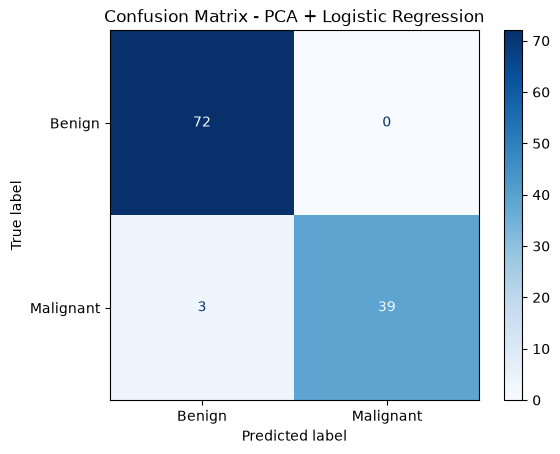

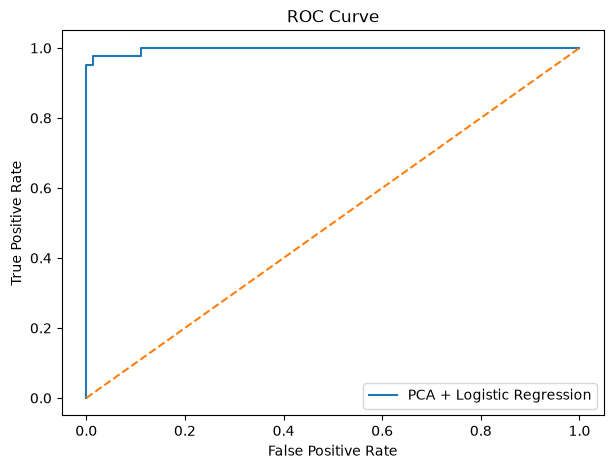

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve
)
import matplotlib.pyplot as plt

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# Build final model
final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=10)),
    ("classifier", LogisticRegression(max_iter=2000))
])

# Train
final_model.fit(X_train, y_train)

# Predictions
y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)[:, 1]

# Evaluation
print("FINAL MODEL: PCA + LOGISTIC REGRESSION")
print("---------------------------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Benign", "Malignant"],
    cmap="Blues"
)
plt.title("Confusion Matrix - PCA + Logistic Regression")
plt.show()

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label="PCA + Logistic Regression")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

FINAL MODEL: PCA + LOGISTIC REGRESSION
---------------------------------------
Accuracy: 0.9737
Precision: 1.0
Recall: 0.9286
F1 Score: 0.963
ROC-AUC: 0.997

Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98        72
           1       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



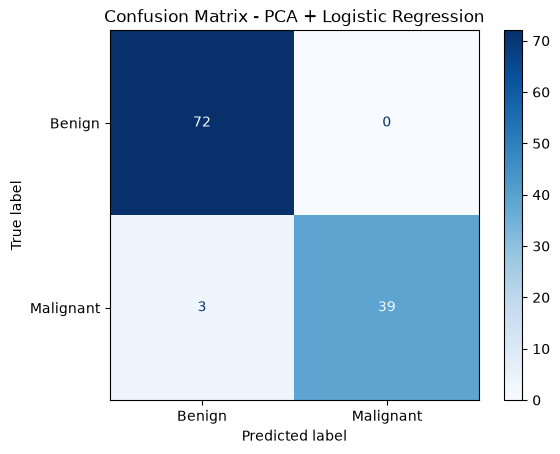

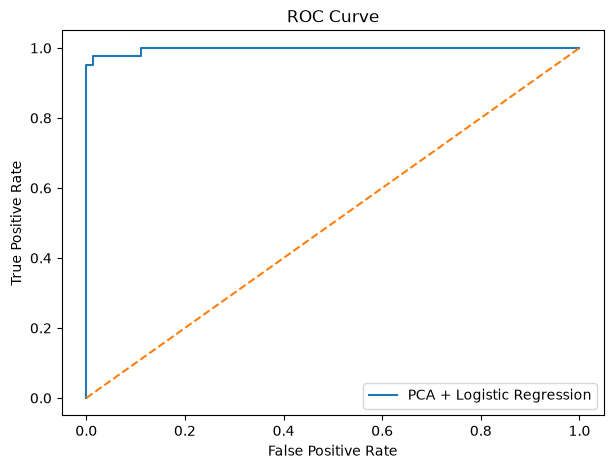

In [15]:


from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve
)
import matplotlib.pyplot as plt

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# Build final model
final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=10)),
    ("classifier", LogisticRegression(max_iter=2000))
])

# Train
final_model.fit(X_train, y_train)

# Predictions
y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)[:, 1]

# Evaluation
print("FINAL MODEL: PCA + LOGISTIC REGRESSION")
print("---------------------------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Benign", "Malignant"],
    cmap="Blues"
)
plt.title("Confusion Matrix - PCA + Logistic Regression")
plt.show()

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label="PCA + Logistic Regression")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [16]:
## 3. Model Explainability using SHAP

Background dataset has 455 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=455 when initializing the masker.


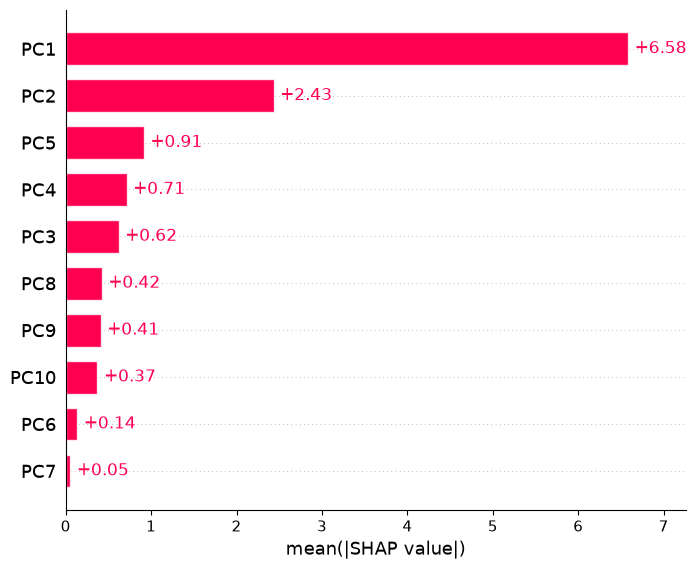

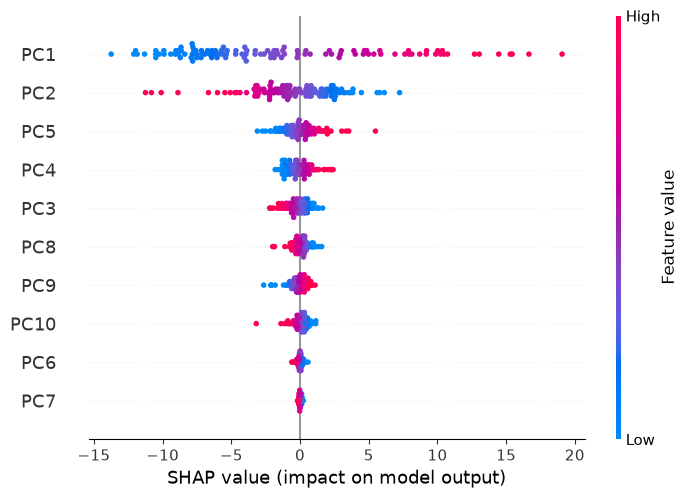

In [17]:

import shap
import pandas as pd
import matplotlib.pyplot as plt

# Transform data using the trained pipeline
X_train_scaled = final_model.named_steps["scaler"].transform(X_train)
X_test_scaled = final_model.named_steps["scaler"].transform(X_test)

X_train_pca = final_model.named_steps["pca"].transform(X_train_scaled)
X_test_pca = final_model.named_steps["pca"].transform(X_test_scaled)

# Give meaningful names to PCA components
component_names = [f"PC{i+1}" for i in range(10)]

X_train_pca_df = pd.DataFrame(
    X_train_pca, columns=component_names
)

X_test_pca_df = pd.DataFrame(
    X_test_pca, columns=component_names
)

# Explain Logistic Regression predictions
classifier = final_model.named_steps["classifier"]

explainer = shap.LinearExplainer(
    classifier, X_train_pca_df
)

shap_values = explainer(X_test_pca_df)

# Global feature importance
shap.plots.bar(shap_values)

# Distribution of component contributions
shap.plots.beeswarm(shap_values)


In [18]:
import shap
print(shap.__version__)

0.54.1


In [19]:
import sys
print(sys.executable)

c:\Users\sk\OneDrive\Desktop\breastCancer-research\.venv\Scripts\python.exe


In [20]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# Recreate final model
final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=10)),
    ("classifier", LogisticRegression(max_iter=2000))
])

# Train model
final_model.fit(X_train, y_train)

print("Final model trained successfully!")

Final model trained successfully!


Background dataset has 455 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=455 when initializing the masker.


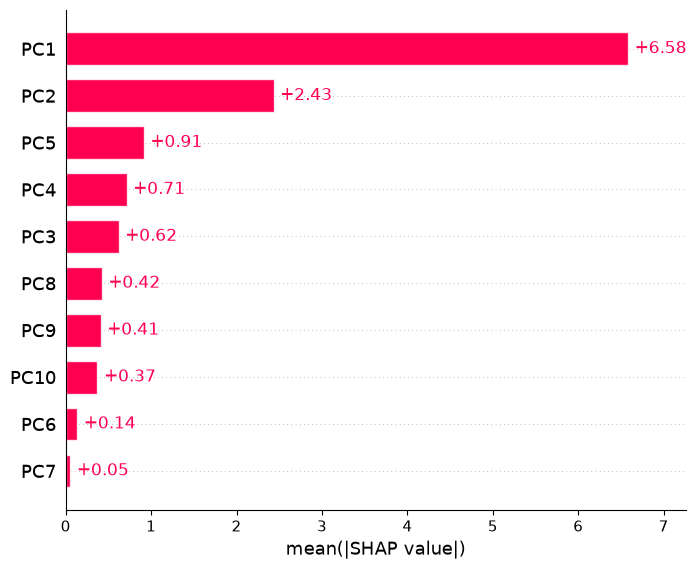

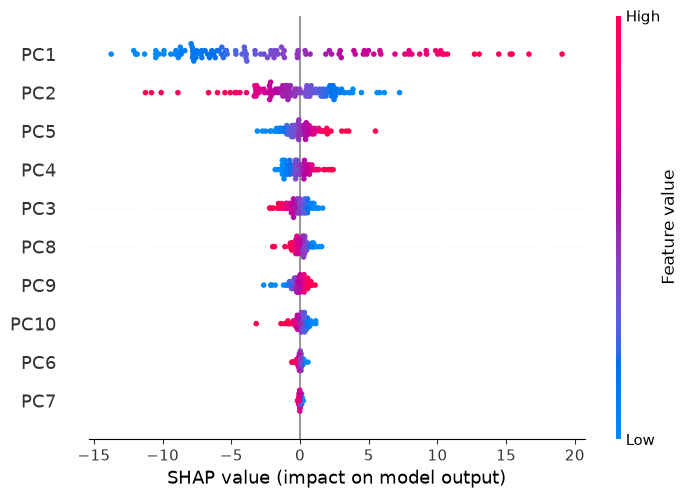

In [21]:
import shap
import pandas as pd
import matplotlib.pyplot as plt

# Transform training and testing data
X_train_scaled = final_model.named_steps["scaler"].transform(X_train)
X_test_scaled = final_model.named_steps["scaler"].transform(X_test)

X_train_pca = final_model.named_steps["pca"].transform(X_train_scaled)
X_test_pca = final_model.named_steps["pca"].transform(X_test_scaled)

# Create component names
component_names = [f"PC{i+1}" for i in range(10)]

X_train_pca_df = pd.DataFrame(
    X_train_pca, columns=component_names
)

X_test_pca_df = pd.DataFrame(
    X_test_pca, columns=component_names
)

# SHAP explainer
classifier = final_model.named_steps["classifier"]

explainer = shap.LinearExplainer(
    classifier, X_train_pca_df
)

shap_values = explainer(X_test_pca_df)

# Global feature importance
shap.plots.bar(shap_values)

# Individual contribution distribution
shap.plots.beeswarm(shap_values)

In [22]:
import joblib
import os

os.makedirs("../results", exist_ok=True)

joblib.dump(
    final_model,
    "../results/best_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!
